# Lagrange: interpolación directa

Con m nodos distintos se construye un polinomio de grado ≤ m−1. x e y son datos; z son puntos nuevos.

**Uso:** ejecuta los imports y el bloque del caso que necesites. Cada ejemplo empieza con sus propios datos. `def` se usa solo para expresiones matemáticas.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Evaluar y graficar

Para cada i, L empieza en 1 y multiplica todos los factores con j distinto de i. Después se acumula y[i]*L. z puede ser un arreglo: NumPy calcula todos los puntos a la vez.

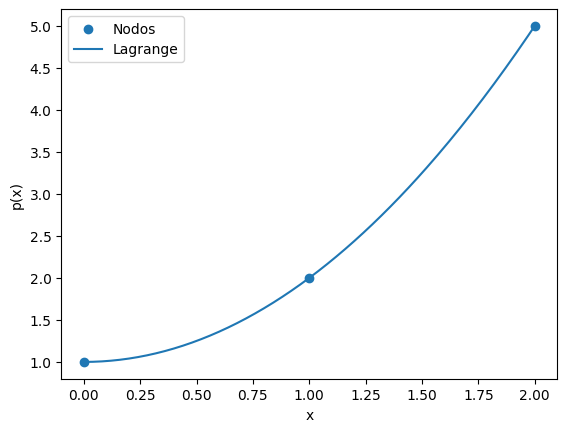

In [2]:
x=np.array([0.,1.,2.])
y=np.array([1.,2.,5.])
assert len(x)==len(y) and len(x)>0 and len(np.unique(x))==len(x)
z=np.linspace(x.min(),x.max(),201) # o z=np.array([0.5])
p=np.zeros_like(z,dtype=float)
for i in range(len(x)):
    L=np.ones_like(z,dtype=float)
    for j in range(len(x)):
        if j!=i:
            L *= (z-x[j])/(x[i]-x[j])
    p += y[i]*L
plt.scatter(x,y,label='Nodos'); plt.plot(z,p,label='Lagrange'); plt.xlabel('x'); plt.ylabel('p(x)'); plt.legend(); plt.show()
assert np.allclose(p,1+z**2) # solo para estos datos de ejemplo

## 2. Verificación en los nodos

El interpolante debe reproducir y. Aquí se guardan las bases evaluadas en todos los nodos: cada fila selecciona un nodo.

In [3]:
x=np.array([0.,1.,2.]); y=np.array([1.,2.,5.])
z=x.copy()
p=np.zeros(len(z))
for i in range(len(x)):
    L=np.ones(len(z))
    for j in range(len(x)):
        if j!=i:
            L *= (z-x[j])/(x[i]-x[j])
    p += y[i]*L
print(p, 'Coincide:',np.allclose(p,y))
assert np.allclose(p,y)

[1. 2. 5.] Coincide: True


## 3. Si piden coeficientes en potencias

Lagrange evalúa directamente. Para construir sus coeficientes, multiplica los factores de cada base como polinomios. np.polynomial.polynomial.polymul usa orden ascendente. Vandermonde monomial es otra opción si el enunciado lo permite.

In [4]:
x=np.array([0.,1.,2.]); y=np.array([1.,2.,5.])
assert len(x)==len(y) and len(np.unique(x))==len(x)
A=np.zeros(len(x))
for i in range(len(x)):
    L=np.array([1.])
    for j in range(len(x)):
        if j!=i:
            factor=np.array([-x[j],1.])/(x[i]-x[j])
            L=np.polynomial.polynomial.polymul(L,factor)
    A += y[i]*L
print('Coeficientes [a0,a1,...]:',A)
assert np.allclose(A,[1,0,1])

Coeficientes [a0,a1,...]: [1. 0. 1.]


Material de estudio adaptado del notebook de clases y de la versión FC2_C2. Ejemplos de práctica; no son soluciones de las tareas. Comprueba las reglas de uso de material asistido por IA.